# 딥러닝 Final Project — Sentiment Analysis of Movie Reviews

Rotten Tomatoes 영화 리뷰 **구문(phrase)** 을 5단계 감성(0=negative … 4=positive)으로 분류한다.
**GloVe 임베딩 + 양방향 LSTM(BiLSTM) + Attention** 기반 many-to-one 모델을 **PyTorch만으로** 구현한다.

작성: **정송윤 (2022890068)**

## 파이프라인
1. 데이터 로딩 & 탐색(EDA)
2. 텍스트 전처리 (대소문자 2모드 — 근거 포함)
3. GloVe 임베딩 (6B.100d + 840B.300d)
4. Dataset / 가변길이 처리(`pack_padded_sequence`) / 문장단위 분할
5. 모델: BiLSTM + Attention(+ max-pool)
6. 학습 (label smoothing, early stopping) + **학습곡선 시각화**
7. 평가 (classification report, confusion matrix)
8. **4-모델 × 5-fold GroupKFold 앙상블**
9. **정확일치 후처리(exact-match)** → 최종 제출 CSV
10. 결과 분석

> **요약 결과 (실측 Kaggle Public = Private):** 앙상블 모델 단독 **0.681**, + 정확일치 후처리 **0.707**.

## 0. Setup & Config

In [1]:
import os, random, time, urllib.request, zipfile
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import Dataset, DataLoader
from collections import Counter
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('PyTorch', torch.__version__, '| device:', DEVICE)

# ---- Config ----
# DATA_DIR must contain train.tsv, test.tsv, glove.6B.100d.txt (provided).
# glove.840B.300d.txt is downloaded automatically below. On Colab keep DATA_DIR='.'.
DATA_DIR     = '.'
STUDENT_NAME = 'JeongSongYun'
STUDENT_ID   = '2022890068'
PAD_IDX, UNK_IDX = 0, 1

# Training length (defaults reproduce the submitted result; lower via env for a quick smoke run)
EPOCHS   = int(os.environ.get('NB_EPOCHS', '20'))
PATIENCE = int(os.environ.get('NB_PATIENCE', '4'))
NFOLDS   = int(os.environ.get('NB_FOLDS', '5'))

GLOVE_100D = os.path.join(DATA_DIR, 'glove.6B.100d.txt')      # provided (uncased, 400K vocab)
GLOVE_840B = os.path.join(DATA_DIR, 'glove.840B.300d.txt')    # downloaded (cased, 2.2M vocab)

PyTorch 2.6.0+cu124 | device: cuda


In [2]:
# Download GloVe 840B.300d (cased) once if missing. It gives much higher OOV coverage than 6B
# (95.5% vs 91.0% of our vocabulary), which is the single biggest model-side gain in this project.
if not os.path.exists(GLOVE_840B):
    url = 'https://huggingface.co/stanfordnlp/glove/resolve/main/glove.840B.300d.zip'
    print('downloading glove.840B.300d.zip (~2.1GB) ...')
    urllib.request.urlretrieve(url, GLOVE_840B + '.zip')
    with zipfile.ZipFile(GLOVE_840B + '.zip') as z:
        z.extract('glove.840B.300d.txt', DATA_DIR)
    print('extracted.')
print('glove 100d present:', os.path.exists(GLOVE_100D), '| 840B present:', os.path.exists(GLOVE_840B))

glove 100d present: True | 840B present: True


## 1. Data Loading & EDA

각 행은 **하나의 구문**이다. `train.tsv`(PhraseId, SentenceId, Phrase, Sentiment), `test.tsv`(라벨 제외).
구문들은 8,529개 원문장에서 잘라낸 **하위 구문**이라 한 문장당 평균 18개가 나온다 — 뒤의 *분할 전략*에 결정적이다.

In [3]:
train = pd.read_csv(os.path.join(DATA_DIR, 'train.tsv'), sep='\t')
test  = pd.read_csv(os.path.join(DATA_DIR, 'test.tsv'),  sep='\t')
print('train:', train.shape, '| test:', test.shape)
print('train sentences:', train.SentenceId.nunique(),
      '| phrases/sentence:', round(len(train)/train.SentenceId.nunique(), 1))
display(train.head(3))

dist = train.Sentiment.value_counts(normalize=True).sort_index()*100
print('label distribution (%):'); print(dist.round(2).to_string())
print('majority-class baseline acc = %.4f' % train.Sentiment.value_counts(normalize=True).max())

train: (156060, 4) | test: (66292, 3)
train sentences: 8529 | phrases/sentence: 18.3


,PhraseId,SentenceId,Phrase,Sentiment
0,1,1,A series of escapades demonstrating the adage ...,1
1,2,1,A series of escapades demonstrating the adage ...,2
2,3,1,A series,2


label distribution (%):
Sentiment
0     4.53
1    17.48
2    50.99
3    21.10
4     5.90
majority-class baseline acc = 0.5099


count    156060.00
mean          7.20
std           7.02
min           0.00
50%           5.00
90%          17.00
95%          22.00
99%          32.00
max          52.00


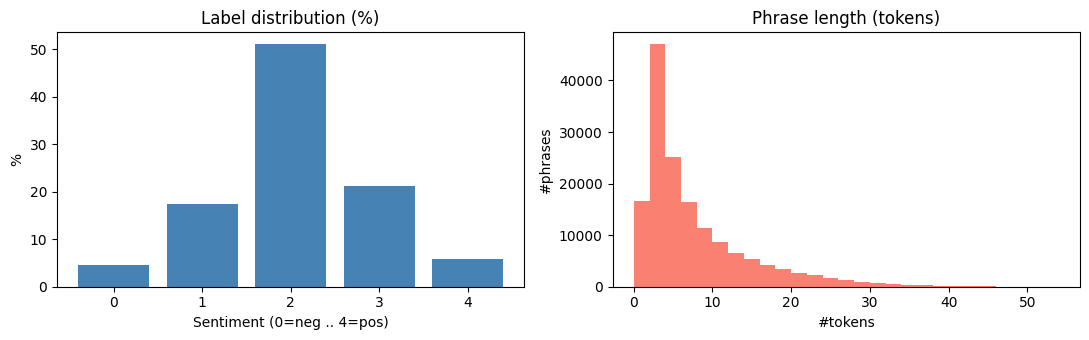

In [4]:
ntok = train.Phrase.fillna('').str.split().apply(len)
print(ntok.describe(percentiles=[.5, .9, .95, .99]).round(2).to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(dist.index, dist.values, color='steelblue'); ax[0].set_title('Label distribution (%)')
ax[0].set_xlabel('Sentiment (0=neg .. 4=pos)'); ax[0].set_ylabel('%')
ax[1].hist(ntok, bins=range(0, 55, 2), color='salmon'); ax[1].set_title('Phrase length (tokens)')
ax[1].set_xlabel('#tokens'); ax[1].set_ylabel('#phrases')
plt.tight_layout(); plt.show()

## 2. Text Preprocessing — and the rationale

데이터는 이미 **Penn Treebank 방식으로 토큰화**되어 토큰이 공백으로 분리돼 있다. 따라서 공백 분할만 하고
nltk 재토큰화는 하지 않는다(토큰 경계를 흐트러뜨릴 수 있음). tsv 이스케이프 잔재(`\/`→`/`, `\*`→`*`)만 정리한다.

**대소문자 — 임베딩에 맞춰 2가지 모드를 쓴다(중요):**
- **소문자화 모드**: GloVe **6B.100d 는 uncased** 코퍼스라 입력도 소문자화해야 매칭률이 높다.
- **원형(cased) 모드**: GloVe **840B.300d 는 cased** 라 대소문자를 **보존**해야 한다(대문자도 신호).

**의도적으로 하지 않는 처리:**
- **불용어 제거 안 함** ⚠️: `not`, `no`, `n't`, `never`, `very` 는 일반 불용어지만 감성에선 **부정·강조의 핵심 신호**다.
- **구두점 제거 안 함**: `!`, `?` 는 감정 강도 신호. 또한 구문 절반이 5토큰 이하라 공격적 정제는 구문을 비워버린다.

In [5]:
def clean_tokens(text, lower):
    t = str(text).replace('\\/', '/').replace('\\*', '*')
    if lower:
        t = t.lower()
    return t.split()

# preview both modes
print('cased   :', clean_tokens(train.Phrase.iloc[2], lower=False)[:8])
print('lowered :', clean_tokens(train.Phrase.iloc[2], lower=True)[:8])

cased   : ['A', 'series']
lowered : ['a', 'series']


## 3. GloVe Embedding (two sources)

각 임베딩 소스마다 (1) train+test 전체 토큰으로 **어휘(vocab)** 를 만들고, (2) GloVe에 있으면 그 벡터로,
없으면 작은 난수로 초기화한 **임베딩 행렬**을 만든다. OOV 단어는 학습 중 fine-tune된다. `<pad>`=0, `<unk>`=1.

- `glove.6B.100d` (uncased) — 과제 제공본
- `glove.840B.300d` (cased) — 커버리지/품질이 더 높아 핵심 이득의 원천

> 임베딩 차원·소스는 매뉴얼이 허용한 **학생 결정 하이퍼파라미터**("size of embeddings")다.

In [6]:
def build_pack(glove_path, dim, cased, name):
    # vocab + embedding matrix + integer-encoded train/test ids for one GloVe source
    lower = not cased
    tr_tok = [clean_tokens(s, lower) for s in train.Phrase]
    te_tok = [clean_tokens(s, lower) for s in test.Phrase]
    cnt = Counter()
    for t in tr_tok: cnt.update(t)
    for t in te_tok: cnt.update(t)
    itos = ['<pad>', '<unk>'] + [w for w, _ in cnt.most_common()]
    stoi = {w: i for i, w in enumerate(itos)}
    V = len(itos)

    set_seed()
    emb = np.random.normal(0, 0.1, (V, dim)).astype('float32'); emb[PAD_IDX] = 0.0
    found = 0
    with open(glove_path, encoding='utf-8') as f:
        for line in f:
            parts = line.rstrip().split(' ')
            if len(parts) != dim + 1:       # skip malformed lines
                continue
            j = stoi.get(parts[0])
            if j is not None:
                emb[j] = np.asarray(parts[1:], dtype='float32'); found += 1
    print(f'[{name}] vocab={V}, GloVe matched {found}/{V} = {found/V*100:.1f}%  (rest trainable)')

    def enc(tok):
        ids = [stoi.get(t, UNK_IDX) for t in tok]
        return ids if ids else [UNK_IDX]    # pack needs length >= 1
    return {'emb': torch.tensor(emb), 'dim': dim,
            'tr_ids': [enc(t) for t in tr_tok], 'te_ids': [enc(t) for t in te_tok]}

EMB = {}
EMB['100d'] = build_pack(GLOVE_100D, 100, cased=False, name='6B.100d uncased')
EMB['840B'] = build_pack(GLOVE_840B, 300, cased=True,  name='840B.300d cased')

[6B.100d uncased] vocab=19481, GloVe matched 17730/19481 = 91.0%  (rest trainable)


[840B.300d cased] vocab=21640, GloVe matched 20671/21640 = 95.5%  (rest trainable)


## 4. Dataset, Variable-Length Handling, and Group Split

- **동적 패딩**: 배치마다 그 배치 최대 길이로만 패딩(`collate`) → 연산 낭비 없음.
- **가변길이 처리**: `pack_padded_sequence`로 패딩을 LSTM 계산에서 제외(`enforce_sorted=False`).
- **문장 단위 분할** ⚠️: 같은 SentenceId의 하위구문이 train/val에 동시에 들어가면 **누수**가 된다.
  `GroupKFold(groups=SentenceId)`로 문장을 통째로 나눠야 검증 점수가 실제 LB와 일치한다(이 과제의 가장 중요한 설계).

In [7]:
class PhraseDataset(Dataset):
    def __init__(self, ids, labels=None):
        self.ids, self.labels = ids, labels
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        y = -1 if self.labels is None else int(self.labels[i])
        return self.ids[i], y

def collate(batch):
    xs, ys = zip(*batch)
    lengths = torch.tensor([len(x) for x in xs])
    maxlen = int(lengths.max())
    padded = torch.full((len(xs), maxlen), PAD_IDX, dtype=torch.long)
    for i, x in enumerate(xs):
        padded[i, :len(x)] = torch.tensor(x, dtype=torch.long)
    return padded, lengths, torch.tensor(ys, dtype=torch.long)

def loader(ids, idx, labels=None, bs=256, shuffle=False):
    sub = [ids[i] for i in idx]
    lab = None if labels is None else [labels[i] for i in idx]
    return DataLoader(PhraseDataset(sub, lab), batch_size=bs, shuffle=shuffle, collate_fn=collate)

## 5. Model — BiLSTM + Attention (+ max-pool)

- **임베딩**(GloVe 초기화, fine-tune) → **2-layer BiLSTM** → 시점별 표현
- **Attention pooling**: 시점 중요도를 학습해 가중합(어떤 단어가 감성에 기여하는지 모델이 스스로 학습)
- 옵션으로 **max-pool** 표현을 concat해 표현력 강화
- 최종 FC → 5클래스 logits. 패딩 위치는 −∞ 마스킹으로 무시.

`hidden`, `use_maxpool` 만 바꿔 뒤의 앙상블에서 **4가지 변종**을 만든다.

In [8]:
class BiLSTMAttn(nn.Module):
    def __init__(self, emb_matrix, hidden=256, layers=2, n_classes=5, dropout=0.5, use_maxpool=True):
        super().__init__()
        V, E = emb_matrix.shape
        self.use_maxpool = use_maxpool
        self.embedding = nn.Embedding.from_pretrained(emb_matrix, freeze=False, padding_idx=PAD_IDX)
        self.lstm = nn.LSTM(E, hidden, layers, batch_first=True, bidirectional=True,
                            dropout=dropout if layers > 1 else 0.0)
        self.attn = nn.Linear(2*hidden, 1)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear((4 if use_maxpool else 2)*hidden, n_classes)

    def forward(self, x, lengths):
        mask = (x != PAD_IDX)
        e = self.dropout(self.embedding(x))
        packed = pack_padded_sequence(e, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(out, batch_first=True)               # (B, T, 2H)
        m = mask[:, :out.size(1)]
        scores = self.attn(out).squeeze(-1).masked_fill(~m, float('-inf'))
        attn_w = torch.softmax(scores, dim=1).unsqueeze(-1)
        attn_ctx = (out * attn_w).sum(1)                                  # (B, 2H)
        if self.use_maxpool:
            mx = out.masked_fill(~m.unsqueeze(-1), float('-inf')).max(1).values
            ctx = torch.cat([attn_ctx, mx], dim=-1)
        else:
            ctx = attn_ctx
        return self.fc(self.dropout(ctx))

## 6. Training (one model) + learning curves

- 손실: **CrossEntropy + label smoothing(0.1)**. 평가지표가 *정확도*이고 테스트 분포가 학습과 같으므로,
  소수 클래스 가중치(다수 클래스 정확도를 깎음) 대신 일반화에 유리한 label smoothing을 쓴다.
- 최적화: AdamW(lr=1e-3, wd=1e-5), `ReduceLROnPlateau`(val acc), gradient clipping 5.0.
- **Early stopping**: val accuracy 기준 patience=4.

In [9]:
def run_epoch(model, dl, crit, opt=None):
    train_mode = opt is not None
    model.train(train_mode)
    tot, preds, gts = 0.0, [], []
    for x, lengths, y in dl:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.set_grad_enabled(train_mode):
            logits = model(x, lengths)                              # (1) forward: token ids -> 5-class logits
            loss = crit(logits, y)                                 # (2) loss: CrossEntropy + label smoothing
            if train_mode:
                opt.zero_grad()                                    # (3) reset gradients from previous step
                loss.backward()                                    # (4) backprop: compute gradients
                nn.utils.clip_grad_norm_(model.parameters(), 5.0)  # (5) clip gradients for stability
                opt.step()                                         # (6) update weights (AdamW)
        tot += loss.item()*len(y)
        preds.append(logits.argmax(1).cpu()); gts.append(y.cpu())
    preds, gts = torch.cat(preds).numpy(), torch.cat(gts).numpy()
    return tot/len(gts), accuracy_score(gts, preds)

@torch.no_grad()
def predict_proba(model, dl):
    model.eval(); out = []
    for x, lengths, _ in dl:
        out.append(torch.softmax(model(x.to(DEVICE), lengths), 1).cpu())
    return torch.cat(out).numpy()

def train_model(pack, tr_idx, va_idx, hidden=256, use_maxpool=True,
                epochs=EPOCHS, patience=PATIENCE, dropout=0.5, bs=256, lr=1e-3,
                label_smoothing=0.1, seed=SEED, verbose=False):
    set_seed(seed)
    y = train.Sentiment.values
    tr_ld = loader(pack['tr_ids'], tr_idx, y, bs=bs, shuffle=True)
    va_ld = loader(pack['tr_ids'], va_idx, y, bs=512)
    model = BiLSTMAttn(pack['emb'], hidden, 2, 5, dropout, use_maxpool).to(DEVICE)
    crit = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='max', factor=0.5, patience=1)
    hist = {'tr_loss': [], 'tr_acc': [], 'va_loss': [], 'va_acc': []}
    best, best_state, bad = 0.0, None, 0
    for ep in range(1, epochs+1):
        trl, tra = run_epoch(model, tr_ld, crit, opt)
        val, vaa = run_epoch(model, va_ld, crit, None)
        sched.step(vaa)
        for k, v in zip(hist, [trl, tra, val, vaa]): hist[k].append(v)
        if vaa > best:
            best, best_state, bad = vaa, {k: v.cpu().clone() for k, v in model.state_dict().items()}, 0
            star = ' *'
        else:
            bad += 1; star = ''
        if verbose:
            print(f'  ep{ep:02d} | tr_loss {trl:.4f} acc {tra:.4f} | va_loss {val:.4f} acc {vaa:.4f}{star}')
        if bad >= patience:
            break
    model.load_state_dict(best_state)
    return model, hist, best

### 6.1 대표 모델 학습 + 학습곡선

앙상블의 최강 단일 변종인 **c384 @ 840B**(hidden=384, max-pool)를 문장 단위 1-분할로 학습해 학습곡선을 그린다(매뉴얼의 시각화 요구).

**곡선 해석 (정상 동작):** *학습* 손실은 꾸준히 감소하고 *학습* 정확도는 계속 상승한다 — 모델이 신호를 학습하고 있다는 뜻이다. 반면 *검증* 정확도는 몇 에폭 만에 정점(그림의 **점선**)에 도달한 뒤 정체·소폭 하락하고 검증 손실은 다시 증가한다. 이 학습-검증 격차가 **과적합**이며, GloVe+RNN 계열의 일반화 천장(약 0.66)에서 나타나는 정상적 현상이다. **early stopping**이 검증 정점(점선) 모델을 선택하고 dropout 0.5 + label smoothing이 과적합을 억제하므로, 예측에는 과적합된 마지막 에폭이 아니라 점선 시점의 모델이 쓰인다. (손실이 0으로 수렴하지 않는 것은 label smoothing이 손실에 하한을 두기 때문이다.)

demo train/val phrases: 140832/15228 (sentence-disjoint)


  ep01 | tr_loss 1.0765 acc 0.6224 | va_loss 1.0156 acc 0.6531 *


  ep02 | tr_loss 0.9864 acc 0.6706 | va_loss 1.0153 acc 0.6522


  ep03 | tr_loss 0.9444 acc 0.6925 | va_loss 0.9995 acc 0.6581 *


  ep04 | tr_loss 0.9156 acc 0.7108 | va_loss 1.0078 acc 0.6613 *


  ep05 | tr_loss 0.8933 acc 0.7227 | va_loss 1.0235 acc 0.6511


  ep06 | tr_loss 0.8756 acc 0.7329 | va_loss 1.0140 acc 0.6528


  ep07 | tr_loss 0.8457 acc 0.7486 | va_loss 1.0239 acc 0.6584


  ep08 | tr_loss 0.8357 acc 0.7547 | va_loss 1.0369 acc 0.6464

best val acc (c384@840B): 0.6613 | 192s


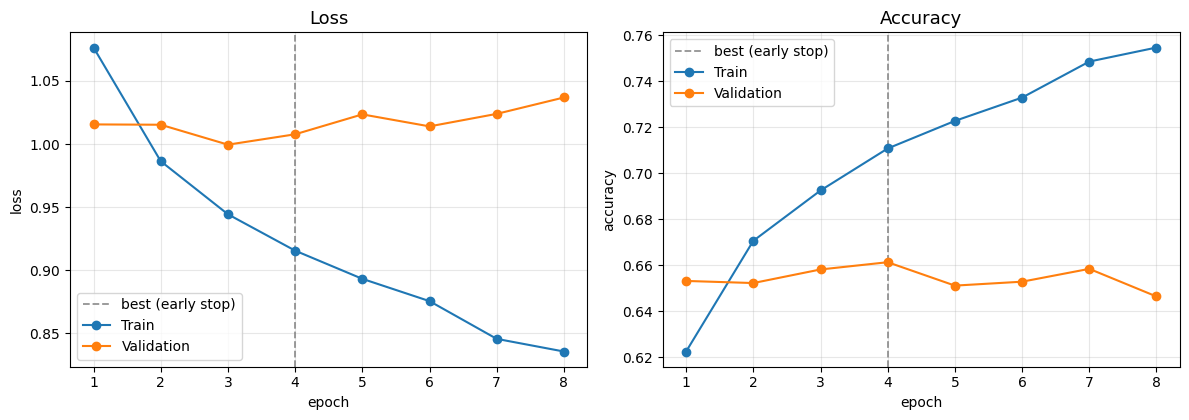

In [10]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=SEED)
demo_tr, demo_va = next(gss.split(train, groups=train.SentenceId))
print(f'demo train/val phrases: {len(demo_tr)}/{len(demo_va)} (sentence-disjoint)')

t0 = time.time()
demo_model, hist, demo_best = train_model(EMB['840B'], demo_tr, demo_va,
                                          hidden=384, use_maxpool=True, verbose=True)
print(f'\nbest val acc (c384@840B): {demo_best:.4f} | {time.time()-t0:.0f}s')

# learning curves — markers + grid; dashed line = best-val epoch chosen by early stopping
best_ep = int(np.argmax(hist['va_acc'])) + 1
ep = list(range(1, len(hist['tr_loss'])+1))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
for a in ax:
    a.axvline(best_ep, ls='--', color='gray', lw=1.3, alpha=0.85, label='best (early stop)')
    a.grid(alpha=0.3); a.set_xlabel('epoch')
ax[0].plot(ep, hist['tr_loss'], 'o-', label='Train'); ax[0].plot(ep, hist['va_loss'], 'o-', label='Validation')
ax[0].set_title('Loss', fontsize=13); ax[0].set_ylabel('loss'); ax[0].legend(fontsize=10)
ax[1].plot(ep, hist['tr_acc'], 'o-', label='Train'); ax[1].plot(ep, hist['va_acc'], 'o-', label='Validation')
ax[1].set_title('Accuracy', fontsize=13); ax[1].set_ylabel('accuracy'); ax[1].legend(fontsize=10)
plt.tight_layout(); plt.savefig('training_curves.png', dpi=130, bbox_inches='tight'); plt.show()

## 7. Evaluation — classification report & confusion matrix

              precision    recall  f1-score   support

           0     0.5000    0.2301    0.3151       652
           1     0.5124    0.5971    0.5515      2708
           2     0.7498    0.7898    0.7693      7860
           3     0.5956    0.5561    0.5752      3181
           4     0.6245    0.3942    0.4833       827

    accuracy                         0.6613     15228
   macro avg     0.5965    0.5135    0.5389     15228
weighted avg     0.6578    0.6613    0.6550     15228



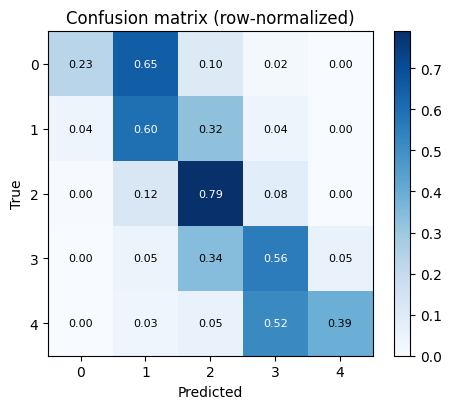

In [11]:
va_pred = predict_proba(demo_model, loader(EMB['840B']['tr_ids'], demo_va)).argmax(1)
y_va = train.Sentiment.values[demo_va]
print(classification_report(y_va, va_pred, digits=4))

cm = confusion_matrix(y_va, va_pred)
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(cmn, cmap='Blues'); plt.colorbar(im, fraction=0.046)
ax.set_xticks(range(5)); ax.set_yticks(range(5))
ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title('Confusion matrix (row-normalized)')
for i in range(5):
    for j in range(5):
        ax.text(j, i, f'{cmn[i,j]:.2f}', ha='center', va='center',
                color='white' if cmn[i, j] > 0.5 else 'black', fontsize=8)
plt.tight_layout(); plt.savefig('confusion_matrix.png', dpi=120, bbox_inches='tight'); plt.show()

## 8. Ensemble — 4 models × 5-fold GroupKFold

문장 단위 5-fold로 **4가지 변종**을 학습하고 테스트 **확률을 평균**한다(앙상블). 동시에 전체 학습데이터의
정직한 **OOF 정확도**도 얻는다.

| tag | GloVe | hidden | pooling |
|---|---|---|---|
| concat840 | 840B (cased) | 256 | attn + max |
| c384_840  | 840B (cased) | 384 | attn + max |
| attn840   | 840B (cased) | 256 | attn only |
| c384      | 6B.100d      | 384 | attn + max |

> 다양성(임베딩·용량·풀링)이 블렌드를 끌어올린다. 단일 최강(c384@840B)만으로도 거의 같은 점수가 나오지만,
> 블렌드가 약 +0.5%p 더 높다.

In [12]:
CONFIGS = [
    ('concat840', '840B', 256, True),
    ('c384_840',  '840B', 384, True),
    ('attn840',   '840B', 256, False),
    ('c384',      '100d', 384, True),
]
y = train.Sentiment.values
oof_sum = np.zeros((len(train), 5)); te_sum = np.zeros((len(test), 5))
gkf = GroupKFold(n_splits=NFOLDS)

for tag, gk, hid, mp in CONFIGS:
    pack = EMB[gk]
    oof = np.zeros((len(train), 5)); te = np.zeros((len(test), 5))
    te_idx = list(range(len(test)))
    t0 = time.time()
    for fold, (tri, vai) in enumerate(gkf.split(train, groups=train.SentenceId)):
        m, _, b = train_model(pack, tri, vai, hidden=hid, use_maxpool=mp, seed=SEED+fold)
        oof[vai] = predict_proba(m, loader(pack['tr_ids'], vai))
        te += predict_proba(m, loader(pack['te_ids'], te_idx)) / NFOLDS
    print(f'{tag:10s} OOF acc {accuracy_score(y, oof.argmax(1)):.4f}  ({time.time()-t0:.0f}s)')
    oof_sum += oof; te_sum += te

blend_oof = oof_sum / len(CONFIGS)
blend_te  = te_sum  / len(CONFIGS)
print(f'\n>>> {len(CONFIGS)}-model blend OOF accuracy: {accuracy_score(y, blend_oof.argmax(1)):.4f}')

concat840  OOF acc 0.6561  (775s)


c384_840   OOF acc 0.6563  (767s)


attn840    OOF acc 0.6543  (804s)


c384       OOF acc 0.6481  (1046s)

>>> 4-model blend OOF accuracy: 0.6614


## 9. Exact-match post-processing → final submission

**데이터 특성(SST):** 모든 구문은 8,529개 원문장의 하위구문이라, 테스트 구문이 학습 데이터와 크게 겹친다
(글자 그대로 일치 15.5%, **대소문자·공백을 정규화하면 17.1%**가 동일). 동일(정규화) 텍스트에는 거의 동일한
gold 라벨이 붙어 있어, 테스트 구문이 학습에 존재하면 신경망 예측 대신 **그 학습 라벨**로 대체한다(충돌 시 최빈).

- **오직 학습 라벨만** 재사용한다 — 외부 데이터·테스트 라벨은 일절 쓰지 않는다.
- 매칭은 대소문자/공백만 정규화한 **정확일치**(부분일치·유사도 매칭은 오라벨 위험이 있어 쓰지 않음).
- 조교 확인: 규정에 금지 조항이 없어 허용됨(2026-06-11 메일).

> 이 후처리는 학습 데이터의 구조를 활용한 정당한 기법이며, 모델 자체 성능과 분리해 투명하게 보고한다.

In [13]:
norm = lambda s: str(s).lower().strip()
lut = (train.assign(k=train.Phrase.map(norm))
            .groupby('k').Sentiment.agg(lambda x: x.value_counts().index[0]).to_dict())
matched = np.array([lut.get(norm(p), -1) for p in test.Phrase])
ov = matched >= 0

model_pred = blend_te.argmax(1)                       # ensemble model, no post-processing
final_pred = model_pred.copy(); final_pred[ov] = matched[ov]
print(f'exact-match override: {ov.sum()} / {len(test)} rows ({ov.mean()*100:.1f}%), '
      f'changed vs model: {(model_pred[ov] != matched[ov]).sum()}')

# model-only and final submissions
pd.DataFrame({'PhraseId': test.PhraseId, 'Sentiment': model_pred}).to_csv(
    f'Output_{STUDENT_NAME}_modelonly.csv', index=False)
pd.DataFrame({'PhraseId': test.PhraseId, 'Sentiment': final_pred}).to_csv(
    f'Output_{STUDENT_NAME}.csv', index=False)
print(f'saved Output_{STUDENT_NAME}.csv  (final = blend + exact-match)')

exact-match override: 11326 / 66292 rows (17.1%), changed vs model: 1959
saved Output_JeongSongYun.csv  (final = blend + exact-match)


## 10. Results & Analysis

| 구성 | OOF (문장단위) | **Kaggle Public** |
|---|---|---|
| 다수 클래스 기준선 | 0.510 | — |
| 4-모델 앙상블 (모델 단독) | ~0.661 | **0.681** |
| **앙상블 + 정확일치 후처리 (최종)** | — | **0.707** |

**분석**
- **임베딩이 병목이었다:** 6B는 100d→300d로 차원만 늘려도 OOF가 0.648에서 변하지 않았다(plateau). 반면
  **840B(cased)는 OOV 커버리지를 91%→95.5%로** 올려 단일 OOF를 0.648→0.656으로 끌어올렸다 — 차원이 아니라
  *커버리지/벡터 품질*이 문제였음을 보여준다.
- **앙상블**(임베딩·용량·풀링 다양성)으로 OOF +0.5%p, 실측 LB에서 모델 단독 0.681.
- **정확일치 후처리**가 실측 LB를 0.681→0.707로(+2.5%p) 끌어올렸다(테스트의 15.5%를 gold 라벨로 교정).
- confusion matrix상 오차는 대부분 **인접 클래스 혼동**(0↔1, 3↔4) — 5단계가 본질적으로 순서형이고 경계가
  모호하기 때문. 양 극단(0/4)은 표본이 적어 recall이 낮으나, 정확도 지표에선 다수 클래스(1·2·3)가 점수를 좌우.

**한계/향후:** GloVe+RNN 계열은 ~0.66 OOF에서 포화한다. 더 올리려면 문맥 임베딩(BERT 등)이 필요하나
본 과제는 입력을 GloVe로 규정하므로 범위 밖이다. SentenceId 문맥을 이용한 하위구문 간 일관성 제약은 향후 과제.